In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from os import name

In [5]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

if len(uploaded_names) == 0:
  raise ValueError('No Image Was Uploaded')

image_name = uploaded_names[0]

image_path = '/content/' + image_name
image = cv2.imread(image_path)

if image is None:
  raise ValueError('Image Could Not Be Read')

print('Input Image:', image_name)
print('Image Shape:', image.shape)

Saving PopEffects.jpeg to PopEffects (1).jpeg
Input Image: PopEffects (1).jpeg
Image Shape: (1049, 700, 3)


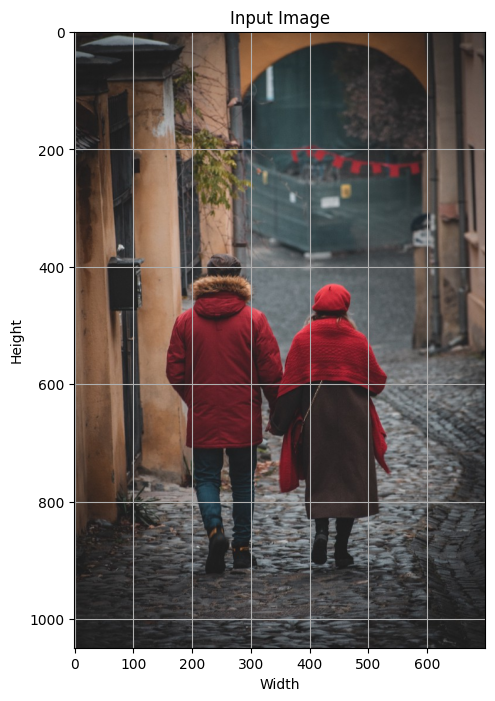

Selected BGR: [[[48 62 81]]]
Selected HSV: [[[ 13 104  81]]]


In [6]:
plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.xlabel('Width')
plt.ylabel('Height')
plt.grid()

plt.show()

x_coordinate = 100
y_coordinate = 100

height, width = image.shape[:2]
if not (0 <= x_coordinate < width and 0 <= y_coordinate < height):
  raise ValueError('Coordinates Are Out Of Bounds')

selected_bgr = image[y_coordinate:y_coordinate + 1, x_coordinate:x_coordinate + 1, :]
selected_hsv = cv2.cvtColor(selected_bgr, cv2.COLOR_BGR2HSV)

print('Selected BGR:', selected_bgr)
print('Selected HSV:', selected_hsv)

In [8]:
def pop_effect(image, lower, upper):
  working_image = image.copy()

  hsv = cv2.cvtColor(working_image, cv2.COLOR_BGR2HSV)

  gray = cv2.cvtColor(working_image, cv2.COLOR_BGR2GRAY)

  mask = cv2.inRange(hsv, lower, upper)

  inverse_mask = cv2.bitwise_not(mask)

  color_region = cv2.bitwise_and(working_image, working_image, mask=mask)

  gray_background = cv2.bitwise_and(gray, gray, mask=inverse_mask)

  gray_background = cv2.merge([gray_background, gray_background, gray_background])

  final_image = cv2.add(color_region, gray_background)

  return final_image

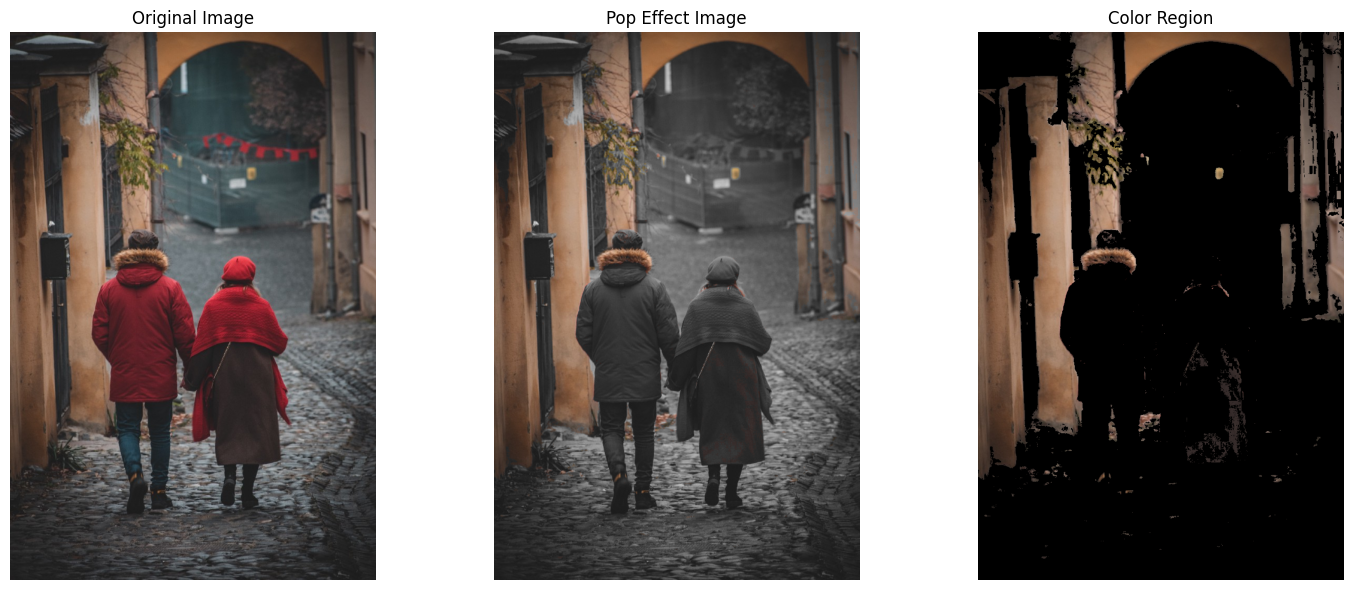

In [10]:
hue_range = 10
selected_hue = selected_hsv[0][0][0]

lower_hue = max(0, selected_hue - hue_range)
upper_hue = min(179, selected_hue + hue_range)

lower = np.array([lower_hue, 50, 50])
upper = np.array([upper_hue, 255, 255])

new_image = pop_effect(image, lower, upper)

hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, lower, upper)
color_image = cv2.bitwise_and(image, image, mask=mask)

plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))
plt.title('Pop Effect Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
plt.title('Color Region')
plt.axis('off')

plt.tight_layout()
plt.show()

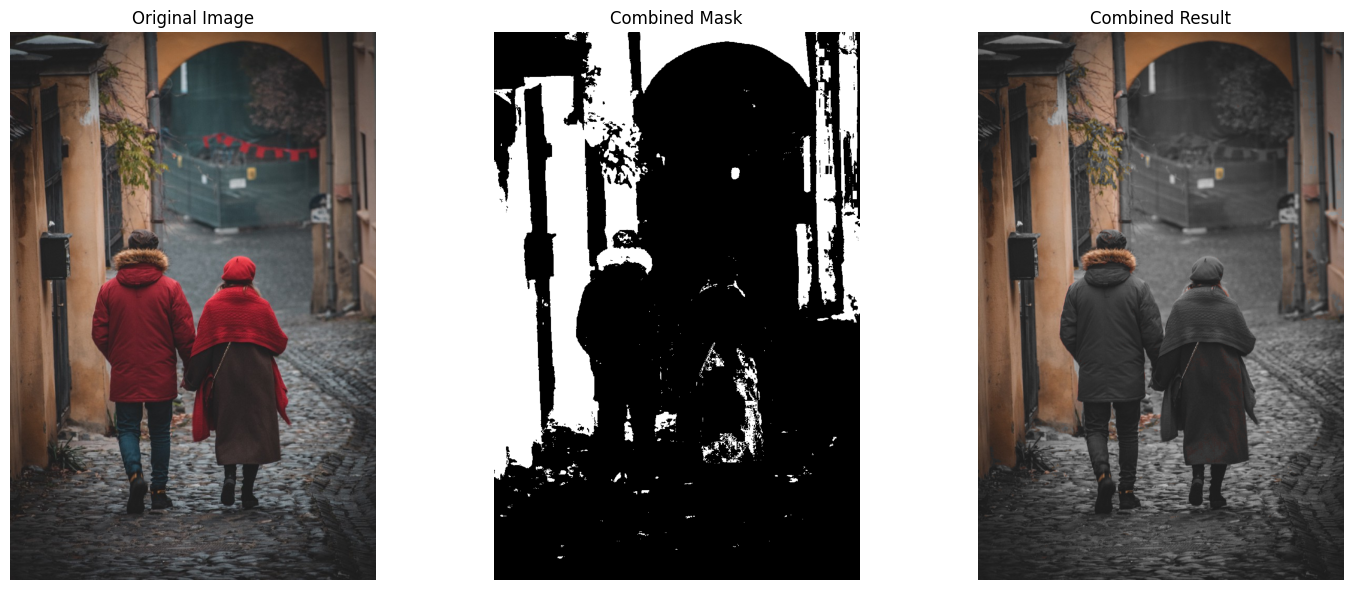

In [12]:
selected_points = [
    (x_coordinate, y_coordinate)
]

hsv_full = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
combined_mask = np.zeros(hsv_full.shape[:2], dtype=np.uint8)

for x, y in selected_points:
  if not (0 <= x < width and 0 <= y < height):
    raise ValueError('Coordinates Are Out Of Bounds')

  point_hue = (hsv_full[y, x, 0])
  point_lower = np.array([point_hue - hue_range, 50, 50])
  point_upper = np.array([
      max(0, point_hue + hue_range),
      255,
      255
  ])

  point_mask = cv2.inRange(hsv_full, point_lower, point_upper)
  combined_mask = cv2.bitwise_or(combined_mask, point_mask)

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
color_region = cv2.bitwise_and(image, image, mask=combined_mask)
gray_background = cv2.bitwise_and(gray_image, gray_image, mask=cv2.bitwise_not(combined_mask))
gray_background = cv2.merge([gray_background, gray_background, gray_background])

combined_result = cv2.add(color_region, gray_background)

plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(combined_mask, cmap='gray')
plt.title('Combined Mask')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(combined_result, cv2.COLOR_BGR2RGB))
plt.title('Combined Result')
plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
cv2.imwrite('/content/color-pop-result.png', new_image)
cv2.imwrite('/content/color-region-result.png', color_image)
cv2.imwrite('/content/combined-result.png', combined_result)

files.download('/content/color-pop-result.png')
files.download('/content/color-region-result.png')
files.download('/content/combined-result.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>